In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load and verify the dataset

In [2]:
import json

data_path = '/content/drive/MyDrive/en-US.jsonl'

with open(data_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

train_data = [r for r in records if r["partition"] == "train"]
dev_data   = [r for r in records if r["partition"] == "dev"]
test_data  = [r for r in records if r["partition"] == "test"]

print(f"Total examples:      {len(records)}")
print(f"Training examples:   {len(train_data)}")
print(f"Validation examples: {len(dev_data)}")
print(f"Test examples:       {len(test_data)}")

assert len(records) == 16521
assert len(train_data) == 11514
assert len(dev_data) == 2033
assert len(test_data) == 2974
print("All split sizes verified.")

print("\nExample record:", train_data[0])

Total examples:      16521
Training examples:   11514
Validation examples: 2033
Test examples:       2974
All split sizes verified.

Example record: {'id': '1', 'locale': 'en-US', 'partition': 'train', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at nine am on friday', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]', 'worker_id': '1'}


Preprocessing of data and setup

In [3]:
import json, os, re, time, random, tarfile, urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
SLOT_RE = re.compile(r"\[\s*([^\]:]+?)\s*:\s*([^\]]*?)\s*\]")

def parse_annot(annot_utt):
    tokens, tags, pos = [], [], 0
    for m in SLOT_RE.finditer(annot_utt):
        for w in annot_utt[pos:m.start()].split():
            tokens.append(w); tags.append("O")
        slot_type = m.group(1).strip()
        for i, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(("B-" if i == 0 else "I-") + slot_type)
        pos = m.end()
    for w in annot_utt[pos:].split():
        tokens.append(w); tags.append("O")
    return tokens, tags

def tags_to_spans(tokens, tags):
    """BIO tags -> set of (slot_type, span_text)."""
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != cur_type):
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        elif tag.startswith("I-"):
            cur_words.append(tok)
        else:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans

def preprocess(records):
    out = []
    for r in records:
        tokens, tags = parse_annot(r["annot_utt"])
        assert tokens == r["utt"].split(), f"Token mismatch in id {r['id']}"
        out.append({"id": r["id"], "tokens": tokens, "slot_tags": tags,
                    "intent": r["intent"], "gold_spans": tags_to_spans(tokens, tags)})
    return out

train_proc, dev_proc, test_proc = preprocess(train_data), preprocess(dev_data), preprocess(test_data)

# Vocab and label maps are built from the training split only
PAD, UNK = "<pad>", "<unk>"
word_counts = Counter(t.lower() for ex in train_proc for t in ex["tokens"])
word2id = {PAD: 0, UNK: 1}
for w, _ in word_counts.most_common():
    word2id[w] = len(word2id)

intent2id = {it: i for i, it in enumerate(sorted({ex["intent"] for ex in train_proc}))}
id2intent = {i: it for it, i in intent2id.items()}

# B- and I- for every slot type (I-transport_type only appears in test)
slot_types = sorted({t[2:] for ex in train_proc for t in ex["slot_tags"] if t != "O"})
slot2id = {"O": 0}
for st in slot_types:
    slot2id["B-" + st] = len(slot2id)
    slot2id["I-" + st] = len(slot2id)
id2slot = {i: s for s, i in slot2id.items()}

print(f"Vocab: {len(word2id)} | Intents: {len(intent2id)} | "
      f"Slot types: {len(slot_types)} | BIO tags: {len(slot2id)}")
assert len(intent2id) == 60 and len(slot_types) == 55

def encode(ex):
    return {"input_ids": [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]],
            "slot_ids": [slot2id[t] for t in ex["slot_tags"]],
            "intent_id": intent2id[ex["intent"]]}

SLOT_PAD_ID = -100  # ignored by CrossEntropyLoss

class MassiveDataset(Dataset):
    def __init__(self, proc):
        self.data = [encode(ex) for ex in proc]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

def collate_fn(batch):
    return {
        "input_ids": pad_sequence([torch.tensor(b["input_ids"]) for b in batch],
                                  batch_first=True, padding_value=word2id[PAD]),
        "slot_ids": pad_sequence([torch.tensor(b["slot_ids"]) for b in batch],
                                 batch_first=True, padding_value=SLOT_PAD_ID),
        "lengths": torch.tensor([len(b["input_ids"]) for b in batch]),
        "intent_id": torch.tensor([b["intent_id"] for b in batch]),
    }

train_ds, dev_ds, test_ds = MassiveDataset(train_proc), MassiveDataset(dev_proc), MassiveDataset(test_proc)
print("Example:", train_proc[0]["tokens"], train_proc[0]["slot_tags"], train_proc[0]["intent"])

Vocab: 5304 | Intents: 60 | Slot types: 55 | BIO tags: 111
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'] alarm_set


Shared Evaluation Functions

In [5]:
def intent_accuracy(pred_intents, gold_intents):
    correct = sum(p == g for p, g in zip(pred_intents, gold_intents))
    return 100.0 * correct / len(gold_intents)

def slot_micro_f1(pred_span_sets, gold_span_sets):
    tp = fp = fn = 0
    for pred, gold in zip(pred_span_sets, gold_span_sets):
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    denom = 2 * tp + fp + fn
    return 100.0 * 2 * tp / denom if denom > 0 else 0.0

## Stage 1, original: scikit-learn logistic regression for both tasks

The first Stage-1 attempt, kept as the reference point for the tuned version below. It uses standard scikit-learn
logistic regression with no neural networks and no word vectors:

- **Task 1, intent:** one logistic regression over the words and word pairs of the utterance.
- **Task 2, slots:** one logistic regression that classifies each token's BIO tag on its own.

Every utterance gets an intent label and a set of (slot type, slot span) pairs, scored with the shared evaluation
functions above.

**Basic tuning.** Each model tunes only its regularisation strength `C` on the validation split. The test split is
evaluated once, at the end of this section.

**Run order in Colab:** run the cells for mounting, data loading, setup, preprocessing and shared evaluation functions,
then the cells below in order.

**Hardware.** scikit-learn runs on the CPU, so this section does not use the GPU. It takes about 5 minutes.

### Features

All vocabularies come from the training split only. Words and word pairs that never occur in training are ignored at validation and test time.

- **Task 1, intent:** each utterance becomes a 0/1 vector over the lower-cased words and adjacent word pairs seen in training, for example `set`, `an`, `alarm`, `set an`, `an alarm`.
- **Task 2, slots:** each token becomes its own example. Its features are the current word, the previous word and the next word, each one-hot encoded, for example `w=five`, `prev=at`, `next=am`. `<s>` and `</s>` stand in for the neighbours at the start and end of the utterance. The label is the token's BIO tag, such as `B-time`.

In [6]:
# Original Stage 1 (scikit-learn logistic regression): features and tuning helpers
import joblib
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

SK_DIR = "/content/drive/MyDrive/SC4002"
os.makedirs(SK_DIR, exist_ok=True)

# Task 1: binary bag of lower-cased unigrams and bigrams (vocabulary fitted on train only)
bow_vec = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=True,
                          ngram_range=(1, 2), binary=True)
Xi_train = bow_vec.fit_transform([" ".join(ex["tokens"]) for ex in train_proc])
Xi_dev = bow_vec.transform([" ".join(ex["tokens"]) for ex in dev_proc])
Xi_test = bow_vec.transform([" ".join(ex["tokens"]) for ex in test_proc])
yi_train = [ex["intent"] for ex in train_proc]

# Task 2: one example per token with one-hot current / previous / next word (vocabulary fitted on train only)
def token_features(tokens):
    words = [t.lower() for t in tokens]
    padded = ["<s>"] + words + ["</s>"]
    return [{"w=" + padded[i + 1]: 1, "prev=" + padded[i]: 1, "next=" + padded[i + 2]: 1}
            for i in range(len(words))]

tok_vec = DictVectorizer()
Xs_train = tok_vec.fit_transform([f for ex in train_proc for f in token_features(ex["tokens"])])
Xs_dev = tok_vec.transform([f for ex in dev_proc for f in token_features(ex["tokens"])])
Xs_test = tok_vec.transform([f for ex in test_proc for f in token_features(ex["tokens"])])
ys_train = [tag for ex in train_proc for tag in ex["slot_tags"]]

def spans_from_token_tags(proc, flat_tags):
    """Split the flat per-token predictions back into utterances and convert BIO tags to (type, span) sets."""
    spans, i = [], 0
    for ex in proc:
        n = len(ex["tokens"])
        spans.append(tags_to_spans(ex["tokens"], [str(t) for t in flat_tags[i:i + n]]))
        i += n
    assert i == len(flat_tags)
    return spans

gold_intents_dev = [ex["intent"] for ex in dev_proc]
gold_spans_dev = [ex["gold_spans"] for ex in dev_proc]

def intent_dev_score(model):
    return intent_accuracy(list(model.predict(Xi_dev)), gold_intents_dev)

def slot_dev_score(model):
    return slot_micro_f1(spans_from_token_tags(dev_proc, model.predict(Xs_dev)), gold_spans_dev)

def tune(name, make_model, grid, X_train, y_train, dev_score):
    """Fit one model per grid value on train and keep the one with the best validation score."""
    best, scores = {"score": -1.0}, {}
    for value in grid:
        t0 = time.time()
        model = make_model(value).fit(X_train, y_train)
        scores[value] = dev_score(model)
        print(f"{name} | {value} | val {scores[value]:.2f} | {time.time() - t0:.1f}s")
        if scores[value] > best["score"]:
            best = {"value": value, "model": model, "score": scores[value]}
        del model
    print(f"Selected {best['value']} | val {best['score']:.2f}")
    return best, scores

def lr_size(model):
    return model.coef_.size + model.intercept_.size

print(f"Task 1: {Xi_train.shape[0]:,} training utterances x {Xi_train.shape[1]:,} n-gram features")
print(f"Task 2: {Xs_train.shape[0]:,} training tokens x {Xs_train.shape[1]:,} word features | "
      f"{len(set(ys_train))} BIO tags seen in training")

Task 1: 11,514 training utterances x 29,618 n-gram features
Task 2: 79,732 training tokens x 14,838 word features | 107 BIO tags seen in training


### Logistic regression, Task 1: intent classification

Multinomial logistic regression over the n-gram vector. For each of the 60 intents, the model adds up a learned weight for every word and word pair present in the utterance, plus a bias. Softmax turns the 60 scores into probabilities, and the prediction is the most probable intent.

- **Training:** scikit-learn's default solver (L-BFGS) minimises cross-entropy plus an L2 penalty on the weights.
- **Tuning:** `C` is the inverse regularisation strength. A small `C` keeps weights small and simple, and a large `C` lets the model fit the training data more closely. `C = 1` is scikit-learn's default. The value with the best validation intent accuracy is kept.
- **Size:** one weight per feature per intent, plus 60 biases.

In [7]:
# Logistic regression, Task 1: intent classifier, C tuned on validation intent accuracy
LR_C_GRID = [0.1, 1.0, 10.0]
lr_intent, lr_intent_scores = tune(
    "LogReg intent | C", lambda c: LogisticRegression(C=c, max_iter=2000),
    LR_C_GRID, Xi_train, yi_train, intent_dev_score)
print(f"Parameters: {lr_size(lr_intent['model']):,}")

LogReg intent | C | 0.1 | val 77.67 | 14.9s
LogReg intent | C | 1.0 | val 83.96 | 20.1s
LogReg intent | C | 10.0 | val 84.51 | 24.0s
Selected 10.0 | val 84.51
Parameters: 1,777,140


### Logistic regression, Task 2: slot filling as per-token classification

The same model applied to tokens. Each token is classified on its own into one of the BIO tags, using only its current, previous and next word. The predicted tags are then turned into (slot type, slot span) pairs with the shared `tags_to_spans` function.

- **Limitation:** each tag is chosen independently, so nothing stops an invalid sequence such as `O` followed by `I-time`. `tags_to_spans` treats an `I-` tag that does not continue a span as the start of a new span.
- **Tuning:** `C` again, chosen by validation slot micro F1.
- **Size:** one weight per word feature per BIO tag seen in training, plus one bias per tag.

In [8]:
# Logistic regression, Task 2: per-token BIO tagger, C tuned on validation slot micro F1
lr_slot, lr_slot_scores = tune(
    "LogReg slots | C", lambda c: LogisticRegression(C=c, max_iter=2000),
    LR_C_GRID, Xs_train, ys_train, slot_dev_score)
print(f"Parameters: {lr_size(lr_slot['model']):,}")

LogReg slots | C | 0.1 | val 47.32 | 37.0s
LogReg slots | C | 1.0 | val 66.67 | 72.0s
LogReg slots | C | 10.0 | val 71.07 | 98.4s
Selected 10.0 | val 71.07
Parameters: 1,587,773


### Final evaluation of the original logistic regression on validation and test

The selected models are saved to Drive, reloaded, and evaluated once on the validation and test splits. The reloaded
validation scores must match the tuning scores. Size is the number of weights and biases.

In [9]:
# Save the selected models, reload them, and evaluate once on validation and test
SK_CKPT = os.path.join(SK_DIR, "stage1_logreg_original.joblib")
joblib.dump({"lr_intent": lr_intent["model"], "lr_slot": lr_slot["model"],
             "selected": {"lr_intent_C": lr_intent["value"], "lr_slot_C": lr_slot["value"]},
             "bow_vocab": bow_vec.vocabulary_, "tok_vocab": tok_vec.vocabulary_}, SK_CKPT, compress=3)
ckpt_sk = joblib.load(SK_CKPT)
assert ckpt_sk["bow_vocab"] == bow_vec.vocabulary_ and ckpt_sk["tok_vocab"] == tok_vec.vocabulary_, \
    "Vocabulary differs from checkpoint"

def evaluate_sklearn(intent_model, slot_model, proc, Xi, Xs):
    # Every utterance gets an intent label and a set of (slot type, slot span) pairs.
    pred_intents = [str(p) for p in intent_model.predict(Xi)]
    pred_spans = spans_from_token_tags(proc, slot_model.predict(Xs))
    acc = intent_accuracy(pred_intents, [ex["intent"] for ex in proc])
    f1 = slot_micro_f1(pred_spans, [ex["gold_spans"] for ex in proc])
    return {"intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2,
            "pred_intents": pred_intents, "pred_spans": pred_spans}

orig_size = lr_size(ckpt_sk["lr_intent"]) + lr_size(ckpt_sk["lr_slot"])
assert orig_size <= 20_000_000, "Parameter count exceeds 20M"
orig_results = {"Validation": evaluate_sklearn(ckpt_sk["lr_intent"], ckpt_sk["lr_slot"], dev_proc, Xi_dev, Xs_dev),
                "Test": evaluate_sklearn(ckpt_sk["lr_intent"], ckpt_sk["lr_slot"], test_proc, Xi_test, Xs_test)}
assert round(orig_results["Validation"]["intent_acc"], 2) == round(lr_intent["score"], 2), "intent score mismatch"
assert round(orig_results["Validation"]["slot_f1"], 2) == round(lr_slot["score"], 2), "slot score mismatch"

print(f"Loaded checkpoint: {SK_CKPT}")
print("Selected settings:", ckpt_sk["selected"])
print(f"Parameters: {orig_size:,} (within the 20M cap)")
for split in ("Validation", "Test"):
    r = orig_results[split]
    print(f"{split:<11}| intent acc: {r['intent_acc']:.2f} | slot F1: {r['slot_f1']:.2f} | combined: {r['combined']:.2f}")

print("\nExample outputs (test):")
for i in range(3):
    ex = test_proc[i]
    print(f"  '{' '.join(ex['tokens'])}'")
    print(f"     gold: {ex['intent']} {sorted(ex['gold_spans'])}")
    print(f"     pred: {orig_results['Test']['pred_intents'][i]} {sorted(orig_results['Test']['pred_spans'][i])}")

Loaded checkpoint: /content/drive/MyDrive/SC4002/stage1_logreg_original.joblib
Selected settings: {'lr_intent_C': 10.0, 'lr_slot_C': 10.0}
Parameters: 3,364,913 (within the 20M cap)
Validation | intent acc: 84.51 | slot F1: 71.07 | combined: 77.79
Test       | intent acc: 82.92 | slot F1: 69.01 | combined: 75.96

Example outputs (test):
  'wake me up at five am this week'
     gold: alarm_set [('date', 'this week'), ('time', 'five am')]
     pred: alarm_set [('date', 'this week'), ('time', 'five am')]
  'quiet'
     gold: audio_volume_mute []
     pred: audio_volume_mute []
  'pink is all we need'
     gold: iot_hue_lightchange [('color_type', 'pink')]
     pred: qa_factoid []


## Stage 1 baseline (final): tuned logistic regression for both tasks

This is the submitted Stage-1 system. It needs only the cells for mounting, data loading, setup, preprocessing and the
shared evaluation functions above. The original logistic regression section does not need to run first, but if it
has, the final table compares the two.

**Architecture.** Two multinomial logistic regressions with no hidden layers, one per task. Each computes
`logits = W x + b` over a sparse 0/1 feature vector `x`, and softmax turns the logits into class probabilities.

| | Task 1: intent | Task 2: slots |
|---|---|---|
| Input | the utterance `utt`, lower-cased and split on whitespace | the same tokens |
| One example is | one utterance | one token |
| Features of `x` | words and adjacent word pairs, the same features as the original | the token's word, its neighbours, adjacent word pairs, prefix/suffix and shape, and the words of the whole utterance (feature groups explained in Task 2 below) |
| Output | one of 60 intents | one of 111 BIO tags per token, then (slot type, slot span) pairs via the shared `tags_to_spans` |

**Loss.** Mean cross-entropy plus `L2 * ||W||^2`. **Optimiser.** Adam, learning rate 0.02, mini-batches of 64
utterances, 20 epochs. All weights start at zero, so the only randomness is the batch order.

**Decoding for slots.** A logistic regression scores each token on its own, so it can output an invalid sequence such as
`O I-time`. Instead of taking the best tag per token, decoding picks the tag sequence with the highest total
log-probability among sequences where every `I-x` follows `B-x` or `I-x`. It adds no weights; it only forbids invalid
BIO sequences. The model is still a per-token logistic regression.

**What changed from the original logistic regression, and why.** The original slot tagger reached 71.07 validation
and 69.01 test slot F1. Its weaknesses were invalid BIO sequences, a context of only one word either side, no spelling
clues for unseen words, and a best `C` at the edge of its grid. Each of these is addressed here and checked on
validation. Training now runs in epochs, so per-epoch losses, scores, times and learning curves are recorded.

**Tuning (validation split only), done separately for each task:**

- **Intent, basic tuning.** Keep the original features and tune only the `L2` strength over a grid from 0 to 1e-4,
  plus the epoch.
- **Slots, full tuning.** First train each candidate feature set at a default `L2 = 1e-5`, which was best in earlier
  experiments, and keep the best set. Then tune `L2` over the same grid for that set, plus the epoch.

For every run, the epoch with the best validation score is kept. The two models share no weights or inputs, so
choosing each one's best run separately also maximises the combined score `(intent accuracy + slot F1) / 2`. The test
split is used once, in the final cell.

**Runtime.** About 10 to 15 minutes on a T4 GPU in total. It runs on CPU too, but much more slowly.

In [10]:
# Tuned logistic regression baseline: features, models, decoding, training loop
import pandas as pd

LR_DIR = "/content/drive/MyDrive/SC4002"
os.makedirs(LR_DIR, exist_ok=True)
LR_CKPT = os.path.join(LR_DIR, "stage1_logreg_tuned.pt")
if device.type != "cuda":
    print("Warning: no GPU found (Runtime > Change runtime type > GPU). This section will be slow on CPU.")

LR_TRAIN = {"lr": 0.02, "batch_size": 64, "epochs": 20}
DEFAULT_L2 = 1e-5
L2_GRID = [0.0, 1e-6, 3e-6, 1e-5, 3e-5, 1e-4]
SPLITS = {"train": train_proc, "dev": dev_proc, "test": test_proc}

# ---------- features (binary; vocabularies fitted on the training split only)
def word_shape(w):
    # "5pm" -> "0a", "10:30" -> "0:0", "olly" -> "a": digits -> 0, letters -> a, repeats collapsed
    return re.sub(r"(.)\1+", r"\1", re.sub(r"[0-9]", "0", re.sub(r"[a-z]", "a", w)))

def intent_feature_strings(tokens):
    # Same features as the original: lower-cased words and adjacent word pairs (<s>, </s> mark the ends)
    w = [t.lower() for t in tokens]
    p = ["<s>"] + w + ["</s>"]
    return {"w=" + x for x in w} | {"w2=" + a + "|" + b for a, b in zip(p, p[1:])}

def slot_feature_strings(tokens, groups):
    # One feature set per token. The base features (word, previous word, next word) are always used.
    w = [t.lower() for t in tokens]
    p = ["<s>", "<s>"] + w + ["</s>", "</s>"]
    utt = {"utt=" + x for x in w} if "utterance" in groups else set()
    out = []
    for i, cur in enumerate(w):
        j = i + 2
        f = {"w0=" + cur, "w-1=" + p[j - 1], "w+1=" + p[j + 1]}
        if "window2" in groups:
            f |= {"w-2=" + p[j - 2], "w+2=" + p[j + 2]}
        if "pairs" in groups:
            f |= {"w-1,w0=" + p[j - 1] + "|" + cur, "w0,w+1=" + cur + "|" + p[j + 1]}
        if "affix" in groups:
            f |= {"pre3=" + cur[:3], "suf2=" + cur[-2:], "suf3=" + cur[-3:], "shape=" + word_shape(cur)}
        out.append(f | utt)
    return out

ALWAYS_KEEP = ("w=", "w2=", "w0=", "utt=")   # word identities are kept even if seen once; other features need 2+

def build_vocab(feature_sets):
    counts = Counter(f for fs in feature_sets for f in fs)
    return {f: i for i, f in enumerate(sorted(f for f, c in counts.items() if c >= 2 or f.startswith(ALWAYS_KEEP)))}

def prepare_intent():
    feats = {s: [intent_feature_strings(ex["tokens"]) for ex in proc] for s, proc in SPLITS.items()}
    vocab = build_vocab(feats["train"])
    data = {s: [(sorted(vocab[f] for f in fs if f in vocab), intent2id[ex["intent"]])
                for fs, ex in zip(feats[s], SPLITS[s])] for s in SPLITS}
    return vocab, data

def prepare_slots(groups):
    feats = {s: [slot_feature_strings(ex["tokens"], groups) for ex in proc] for s, proc in SPLITS.items()}
    vocab = build_vocab(fs for utt in feats["train"] for fs in utt)
    data = {s: [([sorted(vocab[f] for f in fs if f in vocab) for fs in utt], [slot2id[t] for t in ex["slot_tags"]])
                for utt, ex in zip(feats[s], SPLITS[s])] for s in SPLITS}
    return vocab, data

# ---------- batches: nn.EmbeddingBag takes a flat list of active feature ids plus the offset where each example starts
def bags(lists):
    ids, offs = [], []
    for l in lists:
        offs.append(len(ids)); ids.extend(l)
    return torch.tensor(ids, dtype=torch.long, device=device), torch.tensor(offs, dtype=torch.long, device=device)

def intent_batch(items):
    ids, offs = bags([x for x, _ in items])
    return ids, offs, torch.tensor([y for _, y in items], device=device)

def slot_batch(items):
    ids, offs = bags([tok for toks, _ in items for tok in toks])
    y = torch.tensor([t for _, tag_ids in items for t in tag_ids], device=device)
    return ids, offs, y, [len(tag_ids) for _, tag_ids in items]

def eval_batches(task, items, size=256):
    make = intent_batch if task == "intent" else slot_batch
    return [make(items[s:s + size]) for s in range(0, len(items), size)]

# ---------- model
class SparseLogReg(nn.Module):
    # Multinomial logistic regression on a sparse 0/1 vector x: logits = W x + b.
    # EmbeddingBag(mode="sum") adds up the weight rows of the active features, which equals W x.
    def __init__(self, n_feats, n_classes):
        super().__init__()
        self.W = nn.EmbeddingBag(n_feats, n_classes, mode="sum")
        nn.init.zeros_(self.W.weight)
        self.b = nn.Parameter(torch.zeros(n_classes))

    def forward(self, ids, offs):
        return self.W(ids, offs) + self.b

    def l2(self):
        return (self.W.weight ** 2).sum()

def n_params(model):
    return sum(p.numel() for p in model.parameters())

# ---------- BIO-valid decoding: best total log-probability among sequences where I-x only follows B-x or I-x
N_TAGS = len(slot2id)
_names = [id2slot[i] for i in range(N_TAGS)]
_allowed = torch.ones(N_TAGS, N_TAGS, dtype=torch.bool)
_start_ok = torch.ones(N_TAGS, dtype=torch.bool)
for j, tj in enumerate(_names):
    if tj.startswith("I-"):
        _start_ok[j] = False
        for i, ti in enumerate(_names):
            _allowed[i, j] = ti != "O" and ti[2:] == tj[2:]
BIO_TRANS = ((~_allowed).float() * -1e4).to(device)
BIO_START = ((~_start_ok).float() * -1e4).to(device)

def bio_viterbi(logp, lengths):
    B, T, N = logp.shape
    mask = torch.arange(T, device=logp.device)[None, :] < torch.tensor(lengths, device=logp.device)[:, None]
    score = BIO_START + logp[:, 0]
    keep = torch.arange(N, device=logp.device).expand(B, N)
    backptrs = []
    for t in range(1, T):
        best, idx = (score.unsqueeze(2) + BIO_TRANS).max(dim=1)
        m = mask[:, t:t + 1]
        score = torch.where(m, best + logp[:, t], score)
        backptrs.append(torch.where(m, idx, keep))
    tag = score.argmax(dim=1)
    path = [tag]
    for bp in reversed(backptrs):
        tag = bp.gather(1, tag.unsqueeze(1)).squeeze(1)
        path.append(tag)
    return torch.stack(path[::-1], dim=1)

# ---------- evaluation with the shared functions
@torch.no_grad()
def eval_intent(model, batches, proc):
    model.eval()
    preds, loss_sum = [], 0.0
    for ids, offs, y in batches:
        logits = model(ids, offs)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        preds += [id2intent[i] for i in logits.argmax(1).tolist()]
    return {"loss": loss_sum / len(proc), "score": intent_accuracy(preds, [ex["intent"] for ex in proc]),
            "preds": preds}

@torch.no_grad()
def eval_slots(model, batches, proc, constrained=True):
    model.eval()
    spans, loss_sum, n_tok, k = [], 0.0, 0, 0
    for ids, offs, y, lengths in batches:
        logits = model(ids, offs)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        n_tok += len(y)
        logp = pad_sequence(torch.split(F.log_softmax(logits, 1), lengths), batch_first=True)
        paths = bio_viterbi(logp, lengths) if constrained else logp.argmax(2)
        for row, L in zip(paths.tolist(), lengths):
            spans.append(tags_to_spans(proc[k]["tokens"], [id2slot[t] for t in row[:L]]))
            k += 1
    return {"loss": loss_sum / n_tok, "score": slot_micro_f1(spans, [ex["gold_spans"] for ex in proc]),
            "preds": spans}

# ---------- one training run: per-epoch train/val loss, val score and time; keeps the best-validation epoch
def train_run(task, n_feats, data, l2, label, cfg=LR_TRAIN):
    n_classes = len(intent2id) if task == "intent" else N_TAGS
    make_batch = intent_batch if task == "intent" else slot_batch
    evaluate = eval_intent if task == "intent" else eval_slots
    dev_b = eval_batches(task, data["dev"])
    set_seed()
    model = SparseLogReg(n_feats, n_classes).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    rng = random.Random(SEED)
    history, best = [], {"score": -1.0}
    t_start = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        model.train()
        order = list(range(len(data["train"])))
        rng.shuffle(order)
        total, n = 0.0, 0
        for s in range(0, len(order), cfg["batch_size"]):
            batch = make_batch([data["train"][i] for i in order[s:s + cfg["batch_size"]]])
            ce = F.cross_entropy(model(batch[0], batch[1]), batch[2])
            loss = ce + l2 * model.l2()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += ce.item() * len(batch[2]); n += len(batch[2])
        val = evaluate(model, dev_b, dev_proc)
        history.append({"epoch": epoch, "train_loss": total / n, "val_loss": val["loss"],
                        "val_score": val["score"], "epoch_time_s": time.time() - t0})
        if val["score"] > best["score"]:
            best = {"score": val["score"], "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    elapsed = time.time() - t_start
    print(f"{label:<34} | L2 {l2:<7g} | best epoch {best['epoch']:2d} | val {best['score']:.2f} | "
          f"{n_feats:,} features | {elapsed:.0f}s")
    return {"l2": l2, "history": history, "best": best, "time_s": elapsed, "n_feats": n_feats}

def tune_task(task, feature_sets, prepare):
    # Used for the slot tagger. Step 1: feature set at DEFAULT_L2. Step 2: L2 grid for the chosen set.
    # Each run keeps its best epoch.
    print(f"--- {task}: step 1, feature sets at L2 = {DEFAULT_L2:g}")
    feat_runs = {}
    for name, groups in feature_sets.items():
        vocab, data = prepare(groups)
        feat_runs[name] = train_run(task, len(vocab), data, DEFAULT_L2, f"{task} | {name}")
    best_name = max(feat_runs, key=lambda k: feat_runs[k]["best"]["score"])
    groups = feature_sets[best_name]
    vocab, data = prepare(groups)
    print(f"--- {task}: step 2, L2 grid for '{best_name}'")
    l2_runs = {}
    for l2 in L2_GRID:
        l2_runs[l2] = (feat_runs[best_name] if l2 == DEFAULT_L2
                       else train_run(task, len(vocab), data, l2, f"{task} | {best_name}"))
    best_l2 = max(l2_runs, key=lambda k: l2_runs[k]["best"]["score"])
    sel = l2_runs[best_l2]
    print(f"Selected for {task}: features '{best_name}', L2 {best_l2:g}, epoch {sel['best']['epoch']} | "
          f"val {sel['best']['score']:.2f}\n")
    return {"feature_set": best_name, "groups": groups, "vocab": vocab, "data": data, "l2": best_l2, "run": sel,
            "feat_runs": feat_runs, "l2_runs": l2_runs}

### Task 1: intent classifier, basic tuning

The features are the original ones: the lower-cased words and adjacent word pairs of the utterance. Only the `L2`
strength is tuned, over the grid above, and each run keeps its best epoch. The score is validation intent accuracy.

In [11]:
intent_vocab, intent_data = prepare_intent()
intent_l2_runs = {l2: train_run("intent", len(intent_vocab), intent_data, l2, "intent | words + pairs")
                  for l2 in L2_GRID}
intent_best_l2 = max(intent_l2_runs, key=lambda k: intent_l2_runs[k]["best"]["score"])
intent_tuned = {"feature_set": "words + pairs", "groups": (), "vocab": intent_vocab, "data": intent_data,
                "l2": intent_best_l2, "run": intent_l2_runs[intent_best_l2], "feat_runs": {}, "l2_runs": intent_l2_runs}
print(f"Selected for intent: L2 {intent_best_l2:g}, epoch {intent_tuned['run']['best']['epoch']} | "
      f"val intent acc {intent_tuned['run']['best']['score']:.2f}")

pd.DataFrame([{"L2": l2, "best epoch": r["best"]["epoch"], "val intent acc": round(r["best"]["score"], 2),
               "features": r["n_feats"]} for l2, r in intent_l2_runs.items()])

intent | words + pairs             | L2 0       | best epoch  3 | val 85.39 | 32,785 features | 8s
intent | words + pairs             | L2 1e-06   | best epoch  4 | val 85.10 | 32,785 features | 8s
intent | words + pairs             | L2 3e-06   | best epoch  5 | val 85.10 | 32,785 features | 8s
intent | words + pairs             | L2 1e-05   | best epoch 12 | val 85.15 | 32,785 features | 9s
intent | words + pairs             | L2 3e-05   | best epoch  5 | val 84.95 | 32,785 features | 8s
intent | words + pairs             | L2 0.0001  | best epoch 16 | val 84.90 | 32,785 features | 7s
Selected for intent: L2 0, epoch 3 | val intent acc 85.39


,L2,best epoch,val intent acc,features
0,0.000000,3,85.39,32785
1,0.000001,4,85.10,32785
2,0.000003,5,85.10,32785
3,0.000010,12,85.15,32785
4,0.000030,5,84.95,32785
5,0.000100,16,84.90,32785


### Task 2: tuning the slot tagger

The base features of each token are its word, the previous word and the next word, as in the earlier taggers.
Candidate feature groups added on top:

- **`window2`**: the words two positions before and after.
- **`pairs`**: the word pairs (previous, current) and (current, next), for example `at|five` and `five|am`. A linear model
  cannot combine two separate word features by itself, so pairs let it learn that `five` after `at` is a time.
- **`affix`**: the first 3 letters, the last 2 and 3 letters, and the word's shape, for example `0a` for `5pm`. These
  help with unseen words, numbers and times.
- **`utterance`**: every word in the utterance, given to every token. This tells the tagger what the utterance is about,
  for example that `weather` appears, which shifts the likely slot types without using the intent model.

Step 1 compares all groups, all groups minus each one in turn, and the base features alone. That doubles as an ablation
for the report. The score is validation slot micro F1 with BIO-valid decoding. Afterwards, the selected model is also
decoded without the BIO constraint, to show what the constraint adds.

In [12]:
SLOT_GROUPS = ("window2", "pairs", "affix", "utterance")
SLOT_FEATURE_SETS = {"all groups": SLOT_GROUPS}
SLOT_FEATURE_SETS.update({f"all minus {g}": tuple(x for x in SLOT_GROUPS if x != g) for g in SLOT_GROUPS})
SLOT_FEATURE_SETS["base only (word, previous, next)"] = ()
slot_tuned = tune_task("slots", SLOT_FEATURE_SETS, prepare_slots)

# What the BIO-valid decoding adds, on validation, for the selected slot model
_m = SparseLogReg(slot_tuned["run"]["n_feats"], N_TAGS).to(device)
_m.load_state_dict(slot_tuned["run"]["best"]["state"])
_dev_b = eval_batches("slots", slot_tuned["data"]["dev"])
print(f"Selected slot model, val slot F1 | per-token argmax: {eval_slots(_m, _dev_b, dev_proc, constrained=False)['score']:.2f}"
      f" | BIO-valid decoding: {eval_slots(_m, _dev_b, dev_proc)['score']:.2f}")

pd.DataFrame(
    [{"step": "feature set", "setting": k, "L2": DEFAULT_L2, "best epoch": r["best"]["epoch"],
      "val slot F1": round(r["best"]["score"], 2), "features": r["n_feats"]} for k, r in slot_tuned["feat_runs"].items()]
    + [{"step": "L2", "setting": slot_tuned["feature_set"], "L2": l2, "best epoch": r["best"]["epoch"],
        "val slot F1": round(r["best"]["score"], 2), "features": r["n_feats"]} for l2, r in slot_tuned["l2_runs"].items()])

--- slots: step 1, feature sets at L2 = 1e-05
slots | all groups                 | L2 1e-05   | best epoch 18 | val 76.31 | 38,463 features | 18s
slots | all minus window2          | L2 1e-05   | best epoch  4 | val 75.15 | 34,054 features | 16s
slots | all minus pairs            | L2 1e-05   | best epoch 18 | val 75.94 | 22,519 features | 14s
slots | all minus affix            | L2 1e-05   | best epoch 20 | val 74.61 | 35,869 features | 16s
slots | all minus utterance        | L2 1e-05   | best epoch 12 | val 75.20 | 33,161 features | 14s
slots | base only (word, previous, next) | L2 1e-05   | best epoch 14 | val 66.84 | 10,214 features | 10s
--- slots: step 2, L2 grid for 'all groups'
slots | all groups                 | L2 0       | best epoch  3 | val 77.21 | 38,463 features | 17s
slots | all groups                 | L2 1e-06   | best epoch  3 | val 77.19 | 38,463 features | 17s
slots | all groups                 | L2 3e-06   | best epoch  5 | val 77.25 | 38,463 features | 17s
slot

,step,setting,L2,best epoch,val slot F1,features
0,feature set,all groups,0.000010,18,76.31,38463
1,feature set,all minus window2,0.000010,4,75.15,34054
2,feature set,all minus pairs,0.000010,18,75.94,22519
3,feature set,all minus affix,0.000010,20,74.61,35869
4,feature set,all minus utterance,0.000010,12,75.20,33161
5,feature set,"base only (word, previous, next)",0.000010,14,66.84,10214
6,L2,all groups,0.000000,3,77.21,38463
7,L2,all groups,0.000001,3,77.19,38463
8,L2,all groups,0.000003,5,77.25,38463
9,L2,all groups,0.000010,18,76.31,38463


### Selected checkpoint, parameter count and learning curves

Both selected models are saved in one checkpoint file, with their feature vocabularies and training histories. The
train loss is the mean cross-entropy over the epoch without the L2 term, so it is on the same scale as the validation
loss.

Checkpoint file: /content/drive/MyDrive/SC4002/stage1_logreg_tuned.pt
Intent model: epoch 3, L2 0, features 'words + pairs' | val intent acc 85.39
Slot model:   epoch 5, L2 3e-06, features 'all groups' | val slot F1 77.25
Validation combined score: 81.32
Parameters: intent 1,967,160 + slots 4,269,504 = 6,236,664 (all trainable, within the 20M cap)
Elapsed training time | selected intent run 8s | selected slot run 17s | all tuning runs 3.6 min

Intent model (selected run), per epoch:
 epoch  train_loss  val_loss  val intent acc  epoch_time_s
     1      1.3788    0.6965         84.3581        0.8295
     2      0.1903    0.6196         84.9484        0.3672
     3      0.0736    0.5987         85.3910        0.3690
     4      0.0398    0.5915         85.1943        0.3702
     5      0.0257    0.5863         84.8992        0.3618
     6      0.0183    0.5878         85.0467        0.3661
     7      0.0138    0.5881         84.7516        0.3713
     8      0.0116    0.5883         84.

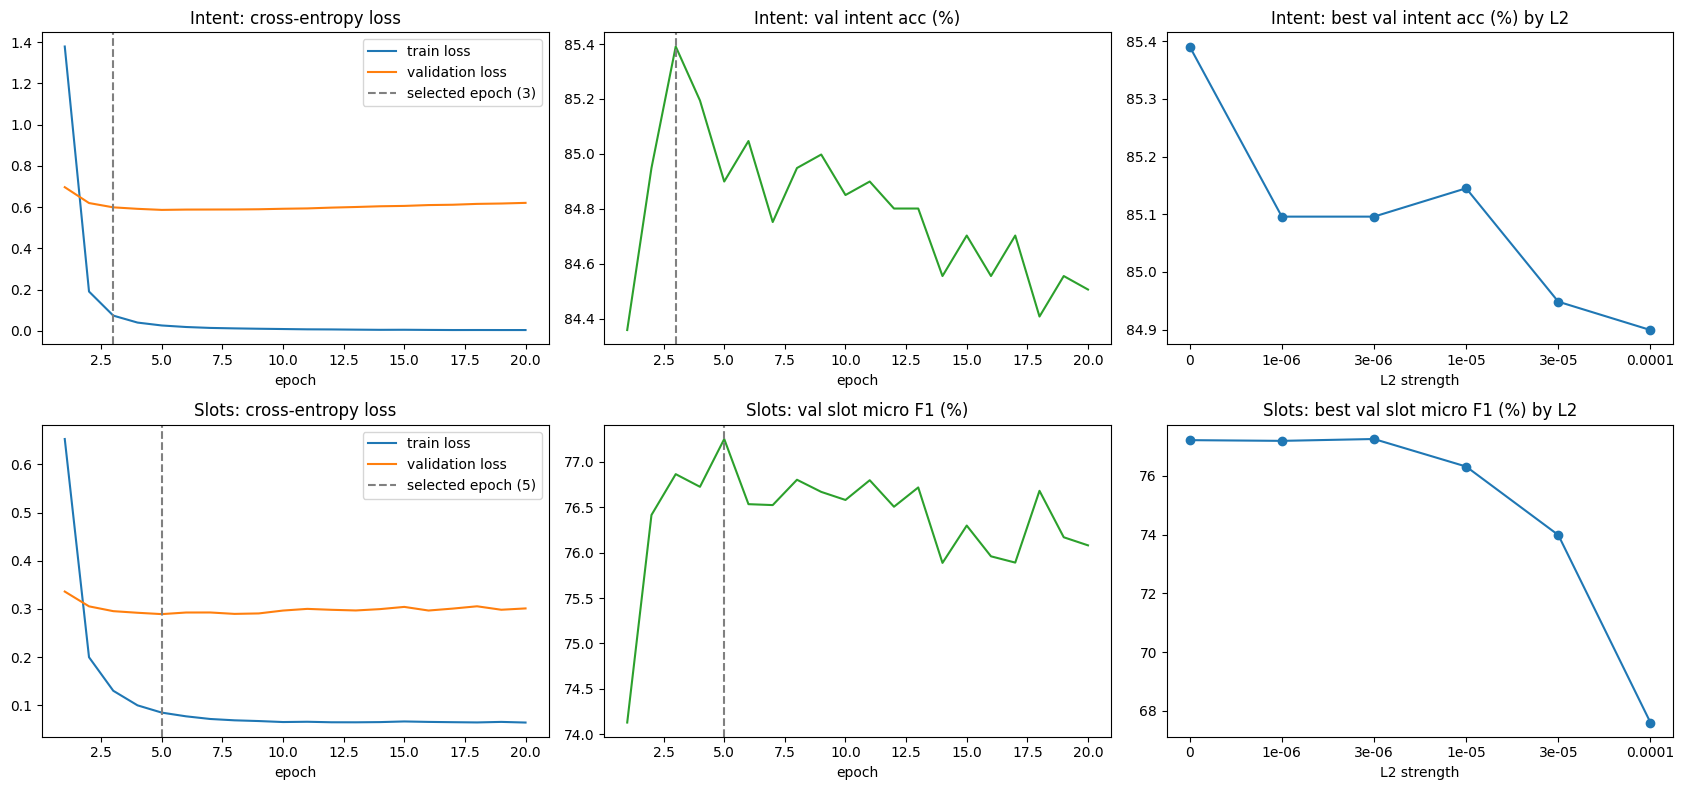

In [13]:
lr_intent_run, lr_slot_run = intent_tuned["run"], slot_tuned["run"]
lr_val_combined = (lr_intent_run["best"]["score"] + lr_slot_run["best"]["score"]) / 2
torch.save({
    "intent": {"state": lr_intent_run["best"]["state"], "epoch": lr_intent_run["best"]["epoch"],
               "l2": intent_tuned["l2"], "feature_set": intent_tuned["feature_set"], "groups": intent_tuned["groups"],
               "vocab": intent_tuned["vocab"], "val_intent_acc": lr_intent_run["best"]["score"],
               "history": lr_intent_run["history"]},
    "slots": {"state": lr_slot_run["best"]["state"], "epoch": lr_slot_run["best"]["epoch"],
              "l2": slot_tuned["l2"], "feature_set": slot_tuned["feature_set"], "groups": slot_tuned["groups"],
              "vocab": slot_tuned["vocab"], "val_slot_f1": lr_slot_run["best"]["score"],
              "history": lr_slot_run["history"]},
    "val_combined": lr_val_combined, "train_cfg": LR_TRAIN,
}, LR_CKPT)

lr_intent_params = lr_intent_run["n_feats"] * len(intent2id) + len(intent2id)
lr_slot_params = lr_slot_run["n_feats"] * N_TAGS + N_TAGS
lr_total_params = lr_intent_params + lr_slot_params
assert lr_total_params <= 20_000_000, "Parameter count exceeds 20M"

print(f"Checkpoint file: {LR_CKPT}")
print(f"Intent model: epoch {lr_intent_run['best']['epoch']}, L2 {intent_tuned['l2']:g}, "
      f"features '{intent_tuned['feature_set']}' | val intent acc {lr_intent_run['best']['score']:.2f}")
print(f"Slot model:   epoch {lr_slot_run['best']['epoch']}, L2 {slot_tuned['l2']:g}, "
      f"features '{slot_tuned['feature_set']}' | val slot F1 {lr_slot_run['best']['score']:.2f}")
print(f"Validation combined score: {lr_val_combined:.2f}")
print(f"Parameters: intent {lr_intent_params:,} + slots {lr_slot_params:,} = {lr_total_params:,} "
      f"(all trainable, within the 20M cap)")
_all_runs = {id(r): r for t in (intent_tuned, slot_tuned)
             for r in list(t["feat_runs"].values()) + list(t["l2_runs"].values())}   # each run counted once
total_tuning_s = sum(r["time_s"] for r in _all_runs.values())
print(f"Elapsed training time | selected intent run {lr_intent_run['time_s']:.0f}s | "
      f"selected slot run {lr_slot_run['time_s']:.0f}s | all tuning runs {total_tuning_s / 60:.1f} min")

# Per-epoch record of the two selected runs
for name, run, metric in (("Intent model", lr_intent_run, "val intent acc"), ("Slot model", lr_slot_run, "val slot F1")):
    print(f"\n{name} (selected run), per epoch:")
    print(pd.DataFrame(run["history"]).rename(columns={"val_score": metric}).round(4).to_string(index=False))

# Learning curves of the selected runs, and validation score against L2
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for row, (name, tuned, metric) in enumerate((("Intent", intent_tuned, "val intent acc (%)"),
                                             ("Slots", slot_tuned, "val slot micro F1 (%)"))):
    h, sel = tuned["run"]["history"], tuned["run"]["best"]["epoch"]
    ep = [r["epoch"] for r in h]
    axes[row, 0].plot(ep, [r["train_loss"] for r in h], label="train loss")
    axes[row, 0].plot(ep, [r["val_loss"] for r in h], label="validation loss")
    axes[row, 1].plot(ep, [r["val_score"] for r in h], color="tab:green")
    for ax in axes[row, :2]:
        ax.axvline(sel, color="gray", linestyle="--", label=f"selected epoch ({sel})")
        ax.set_xlabel("epoch")
    axes[row, 0].set_title(f"{name}: cross-entropy loss"); axes[row, 0].legend()
    axes[row, 1].set_title(f"{name}: {metric}")
    grid = list(tuned["l2_runs"])
    axes[row, 2].plot(range(len(grid)), [tuned["l2_runs"][l2]["best"]["score"] for l2 in grid], marker="o")
    axes[row, 2].set_xticks(range(len(grid)), [f"{l2:g}" for l2 in grid])
    axes[row, 2].set_xlabel("L2 strength"); axes[row, 2].set_title(f"{name}: best {metric} by L2")
plt.tight_layout(); plt.show()

### Final evaluation of the tuned logistic regression baseline

The checkpoint is reloaded into new models with no further training. Features are rebuilt from the training split and
must match the saved vocabularies. The validation scores must equal the ones printed above. The test split is then
evaluated once.

In [14]:
ck_lr = torch.load(LR_CKPT, map_location=device, weights_only=False)

vocab_i, data_i = prepare_intent()
vocab_s, data_s = prepare_slots(ck_lr["slots"]["groups"])
assert vocab_i == ck_lr["intent"]["vocab"] and vocab_s == ck_lr["slots"]["vocab"], "Vocabulary differs from checkpoint"
final_intent = SparseLogReg(len(vocab_i), len(intent2id)).to(device)
final_intent.load_state_dict(ck_lr["intent"]["state"])
final_slots = SparseLogReg(len(vocab_s), N_TAGS).to(device)
final_slots.load_state_dict(ck_lr["slots"]["state"])
lr_total_params = n_params(final_intent) + n_params(final_slots)
assert lr_total_params <= 20_000_000, "Parameter count exceeds 20M"

def evaluate_lr(split, proc):
    # Every utterance gets an intent label and a set of (slot type, slot span) pairs.
    ri = eval_intent(final_intent, eval_batches("intent", data_i[split]), proc)
    rs = eval_slots(final_slots, eval_batches("slots", data_s[split]), proc)
    return {"intent_acc": ri["score"], "slot_f1": rs["score"], "combined": (ri["score"] + rs["score"]) / 2,
            "pred_intents": ri["preds"], "pred_spans": rs["preds"]}

val_lr = evaluate_lr("dev", dev_proc)
test_lr = evaluate_lr("test", test_proc)
assert round(val_lr["intent_acc"], 2) == round(ck_lr["intent"]["val_intent_acc"], 2), "val intent acc differs"
assert round(val_lr["slot_f1"], 2) == round(ck_lr["slots"]["val_slot_f1"], 2), "val slot F1 differs"

print(f"Loaded checkpoint: {LR_CKPT}")
print(f"Validation | intent acc: {val_lr['intent_acc']:.2f} | slot F1: {val_lr['slot_f1']:.2f} | "
      f"combined: {val_lr['combined']:.2f}")
print(f"Test       | intent acc: {test_lr['intent_acc']:.2f} | slot F1: {test_lr['slot_f1']:.2f} | "
      f"combined: {test_lr['combined']:.2f}")

rows = [("Tuned LogReg", split, f"{lr_total_params:,} params", res)
        for split, res in (("Validation", val_lr), ("Test", test_lr))]
if all(n in globals() for n in ("orig_results", "orig_size")):
    rows += [("Original LogReg (sklearn)", split, f"{orig_size:,} params", orig_results[split])
             for split in ("Validation", "Test")]
print(f"\n{'Model':<26}{'Split':<12}{'Size':>20}{'Intent acc':>12}{'Slot F1':>10}{'Combined':>10}")
for name, split, size, res in rows:
    print(f"{name:<26}{split:<12}{size:>20}{res['intent_acc']:>12.2f}{res['slot_f1']:>10.2f}{res['combined']:>10.2f}")

print("\nExample outputs (test):")
for i in range(3):
    ex = test_proc[i]
    print(f"  '{' '.join(ex['tokens'])}'")
    print(f"     gold: {ex['intent']} {sorted(ex['gold_spans'])}")
    print(f"     pred: {test_lr['pred_intents'][i]} {sorted(test_lr['pred_spans'][i])}")

Loaded checkpoint: /content/drive/MyDrive/SC4002/stage1_logreg_tuned.pt
Validation | intent acc: 85.39 | slot F1: 77.25 | combined: 81.32
Test       | intent acc: 84.26 | slot F1: 74.08 | combined: 79.17

Model                     Split                       Size  Intent acc   Slot F1  Combined
Tuned LogReg              Validation      6,236,664 params       85.39     77.25     81.32
Tuned LogReg              Test            6,236,664 params       84.26     74.08     79.17
Original LogReg (sklearn) Validation      3,364,913 params       84.51     71.07     77.79
Original LogReg (sklearn) Test            3,364,913 params       82.92     69.01     75.96

Example outputs (test):
  'wake me up at five am this week'
     gold: alarm_set [('date', 'this week'), ('time', 'five am')]
     pred: alarm_set [('date', 'this week'), ('time', 'five am')]
  'quiet'
     gold: audio_volume_mute []
     pred: audio_volume_mute []
  'pink is all we need'
     gold: iot_hue_lightchange [('color_type', 'p